## a. Data Exploration and Pre-processing

i

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

df=pd.read_csv('../data/student/student-mat.csv', sep=';')

ii

In [26]:
selected_cols=['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']
df=df[selected_cols].copy()

df['schoolsup']=df['schoolsup'].map({'no': 0, 'yes': 1})
df['alc']=(df['Dalc'] + df['Walc'])/2.0
df=df.drop(columns=['Dalc', 'Walc'])
feature_cols=['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
df=df[feature_cols + ['G3']]

print(df.head())

   age  studytime  schoolsup  goout  health  absences  alc  G3
0   18          2          1      4       3         6  1.0   6
1   17          2          0      3       3         4  1.0   6
2   15          2          1      2       3        10  2.5  10
3   15          3          0      2       5         2  1.0  15
4   16          2          0      2       5         4  1.5  10


iii

In [27]:
outlier_counts={}
for col in feature_cols:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3 - q1
    lower_bound=q1 - 1.5*iqr
    upper_bound=q3 + 1.5*iqr
    outliers=df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_counts[col]=len(outliers)

for col, count in outlier_counts.items():
    print(f"{col}: {count}")

age: 1
studytime: 27
schoolsup: 51
goout: 0
health: 0
absences: 15
alc: 9


iv

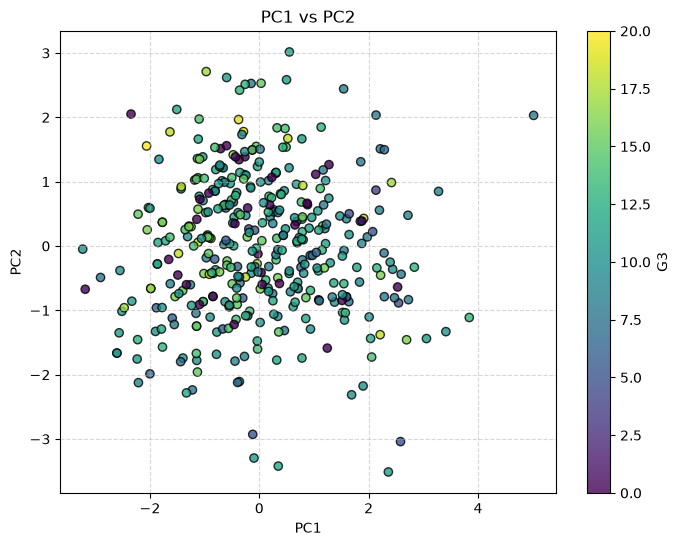

                PC1       PC2
age        0.381940  0.589260
studytime -0.329734  0.385671
schoolsup -0.248184 -0.464202
goout      0.493755 -0.139613
health     0.080545 -0.400925
absences   0.280106  0.182798
alc        0.595871 -0.273677

Top contributing feature to PC1 is alc
Top contributing feature to PC2 is age


In [33]:
X=df[feature_cols].values
y=df['G3'].values

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter=plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.8)
plt.colorbar(scatter, label='G3')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 vs PC2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

loadings=pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=['PC1', 'PC2']
)
print(loadings)

pc1_top=loadings['PC1'].abs().idxmax()
pc2_top=loadings['PC2'].abs().idxmax()
print(f"\nTop contributing feature to PC1 is {pc1_top}")
print(f"Top contributing feature to PC2 is {pc2_top}")

## b. Linear Regression

i

In [42]:
X_train, X_test, y_train, y_test=train_test_split(X_scaled, y, test_size=0.20, random_state=552)

ii

In [43]:
models={
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=0.1),
    'Lasso': Lasso(alpha=0.1)
}

for name, model in models.items():
    model.fit(X_train, y_train)

iii

In [44]:
metrics_data=[]
for name, model in models.items():
    y_pred=model.predict(X_test)
    mae=mean_absolute_error(y_test, y_pred)
    rmse=root_mean_squared_error(y_test, y_pred)
    r2=r2_score(y_test, y_pred)
    metrics_data.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R^2': r2})

metrics_df=pd.DataFrame(metrics_data)
print(metrics_df.to_string(index=False))

            Model      MAE     RMSE      R^2
Linear Regression 3.418009 4.755812 0.028177
            Ridge 3.418062 4.755859 0.028157
            Lasso 3.447073 4.793840 0.012573


Linear Regression is the best model here since it has highest $R^2$, and lowest MAE and RMSE.

iv 

$R^2$ is the proportion of variance in the $G_3$ that's made up by linear combination of standardized features. Low $R^2$ shows that student final grade is significantly influenced by non-linear factors and prior performance not captured by these lifestyle variables.

v


In [45]:
coef_dict={'Feature': feature_cols}
for name, model in models.items():
    coef_dict[name]=model.coef_

coef_df=pd.DataFrame(coef_dict)
intercept_row={'Feature': 'Intercept'}
for name, model in models.items():
    intercept_row[name]=model.intercept_

coef_df=pd.concat([coef_df, pd.DataFrame([intercept_row])], ignore_index=True)
print(coef_df.to_string(index=False))

  Feature  Linear Regression     Ridge     Lasso
      age          -0.781077 -0.780739 -0.630377
studytime           0.444812  0.444655  0.349092
schoolsup          -0.682472 -0.682191 -0.547461
    goout          -0.582519 -0.582312 -0.485602
   health          -0.243324 -0.243227 -0.141569
 absences           0.192800  0.192695  0.072043
      alc           0.037073  0.036909 -0.000000
Intercept          10.629378 10.629365 10.625104


vi

Age is negative relationship, older student in the same academic cohort has lower final grade.

Studytime is positive relationship, an increase in weekly study time grants to a higher predicted final grade.

Schoolsup is negative relationship, student with extra support have lower predicted final grade, but I believe this is a bias since student with lower grade will be assigned support rather than support is lowering their grade.

Goout is negative relationship, higher frequency of going out is associated with lower final grades.

Health is slightly negative relationship, unhealthy student tends to have slight lower final grade.

Absences is slightly positive relationship, meaning absences actually results in slightly higher final grade which is probably also a bias since student with absences may be good enough to miss a few classes.

Alc is negative relationship, the combined alcohol consumption cause worse performance, higher alcohol consumption corresponds to lower predicted final scores.



vii

Ridge ($L_2$): Penalizes $\sum \beta_j^2$, shrinks all coefficients continuously toward zero but not forcing any to  exactlyzero.

Lasso ($L_1$): Penalizes $\sum \vert{}\beta_j\vert{}$, automatic feature selection by zeroing out coefficients with weak explanatory power.

$n \gg p$ ($n=395, p=7$), collinearity is the modest, and $\alpha=0.1$ is small, three models yield similar predictions. Lifestyle features provide modest linear predictive power for $G_3$.

viii

As alpha apporoches infinityu, coefficient magnitudes shrink toward zero. 

Model variance decreases, but bias increases significantly.

Test MAE and RMSE will initially decrease slightly, then increase as underfitting occurs, driving test $R^2$ toward 0.


ix

I say include previous period grades $G_1$ and $G_2$, which is the strongest predictor of $G_3$. 

Or we can create cross-terms between parental education level and educational aspirations.